# N153 — Minimize bank reconstruction; use RankMe only as a constraint

Authorized 5 November 2026. N152's bank controller selected small-rate replay in
46% of updates. Among objective-driven small-rate choices, approximately 64%
predicted worse bank reconstruction than quarter-rate replay: the additive RankMe
reward compensated for it. The bank predictor learned useful executed-action
signal, but the policy lost to fixed replay on incoming and unseen-tail loss.
This experiment changes that selection objective while preserving the substrate.

## Question and arms

Can removing the additive RankMe reward improve reconstruction while retaining
acceptable representation health, compared with fixed replay and the old controller?

1. **fixed_replay:** unchanged quarter-rate replay.
2. **bank_controller:** unchanged N152 bank-loss plus inverse-RankMe score.
3. **loss_constraint:** minimize predicted next normalized bank reconstruction loss;
   RankMe is a replay-relative degradation constraint, never an additive reward.

All arms retain the menu {quarter-rate replay, 1/16-rate replay, quarter-rate
current-five}. One Adam step and five gradient images per positive action. Replay
is .5 current-view loss plus .5 mean loss of four recent images. Every trajectory
starts at the same original full model/Adam/RNG parent; no trained N152 learner or
head transfers. No holds, candidate network forks, or performance-based rollbacks.

## Exact new rule

The online predictor still forecasts relative H1 changes in current-image loss,
bank loss and bank RankMe for each action. Let d_L(a) and d_R(a) denote predicted
relative bank-loss and rank changes. Action 0 is quarter-rate replay. Let q_L(a)
and q_R(a) be the 90th percentiles of absolute bank-loss and rank residuals in that
action's most recent 256 executed-action observations. Initialize residuals using
the same warmup ridge PRESS estimates as N152.

For an alternative to qualify, require:

    d_L(0) - d_L(a) > .25 * (q_L(0) + q_L(a))
    d_R(a) >= d_R(0) - .5 * (q_R(0) + q_R(a))

Require positive finite predicted readings as before. Choose the qualifying action
with lowest d_L(a), or execute quarter-rate replay if none qualifies. Ties follow
the unchanged action order. RankMe cannot compensate for a predicted loss penalty.
Store per-action margins, relative rank floors and eligible flags before execution;
verify every nondefault objective choice satisfies both inequalities.

The rank guard and its .5 coefficient are exactly N152's guard. The loss-margin
coefficient remains .25, applied to bank-loss residuals instead of combined-score
residuals because the objective now contains only bank loss. No new threshold
sweep or outcome-based calibration occurs. These residual-based tolerances are
heuristics, not confidence guarantees. The constraint limits predicted additional
rank degradation relative to replay, not absolute rank decline. Fallback replay
itself can reduce RankMe. Warmup and exploration bypass the gate as before.

## Everything retained from N152

The 256-image FIFO bank contains the latest eligible past images, excludes reserved
initial-audit images, and includes the four replay images. Membership is frozen
before/after each update. The incoming image enters at the next arrival. Each image
keeps its identity-specific reconstruction mask. Freshly measure all per-image
losses and bank embeddings; never use stale cached losses or mixed-model embeddings
as current targets. RankMe uses the same 256-image raw singular spectrum.

Persist per-image losses, admission loss/time and the exact decomposition of bank
change into learning on unchanged members versus membership replacement. Only
the learning term trains the head. Retain the 17-feature predictor, action-specific
ridge alpha=10/intercept=1, train-only warmup scaling, clipped standardized inputs,
and half-life 256 observations of each action. Only the executed action trains.

Controllers cycle actions for 96 updates, then explore one seeded uniform action
every 16 updates. The objective and guard remain fixed; the image model and predictor
learn online. Fixed replay fits the same diagnostic head but never consults it.
Count warmup/exploration outcomes and costs. Retain current-image reconstruction,
norm/cosine, independent audit health, predictions and zero-change error comparisons.

## Matched reuse, not a fresh replication

Only ten unused reserved clips remain. Reuse N152's three 40-clip streams, exact
sample plan, initial-audit identities, masks, action-view seeds and exploration
seeds to isolate the objective change. These data have already informed the design:
this is a development follow-up, not an untouched confirmation or nine independent
new datasets. All arms restart from the original parent. No future audit reading
enters any decision, although historical aggregate results motivated this design.

Rerun both reference arms rather than merely importing their outcomes. Their final
full learner fingerprints, online heads, all original trace fields, audits and tail
readings must exactly reproduce N152. This verifies that the experimental substrate
was preserved. The new controller's comparison remains paired on the same streams.

Per stream: 3,840 images; training arrivals 0..3775; initial 64-image audit from
the first 255; no updates until index 320; 256-image bank available at that point.
Updates at indices 320..3775: 3,456 optimizer steps and 17,280 gradient images per
arm. Reserve indices 3776..3839 as the final-only future tail. Nine trajectories:
31,104 optimizer updates and 155,520 gradient images. Equal gradient work and step
counts do not imply equal LR dose or production overhead.

## Evaluation and interpretation

Primary contrasts: new controller versus fixed replay; new versus additive bank
controller. Report mean incoming pre-update reconstruction, final initial-context
and unseen-tail reconstruction/RankMe, plus older-bank/recent-window health and
common-checkpoint means. Report the actual controller-bank loss trajectory too.
Keep loss and RankMe separate as evaluation outcomes; no composite winner score.
Report all stream-level effects and equally weighted means, not frame-level
significance tests or best checkpoints. Three streams share one original parent.

Mechanism checks: action fractions, cumulative LR dose, objective switches with
predicted bank-loss penalties (must be zero for the new rule), eligibility/margins,
and observed prediction error against zero-change persistence. Executed-action
prediction accuracy does not establish counterfactual ranking accuracy. Actual
rank degradation remains possible despite the heuristic gate; report it.

If reconstruction improves relative to the additive controller without substantial
health damage, additive rank reward was part of the problem. If the new controller
also beats fixed replay, selective bank-loss optimization has incremental value.
If it collapses to replay, a useful conservative rule may have been found but no
selection benefit established. If it still loses, investigate action ranking or H1
horizon mismatch rather than claiming bank monitoring is useless. If rank worsens,
the guard needs scrutiny; this run cannot establish guaranteed protection.

Same incoming/current, independent audit, bank-history and action plots as N152;
no task labels, probes, kNN, or fine tuning. Report measurement/training/head/audit
costs separately. A production fixed-replay learner would omit head/measurement work.

## Reliability and execution

Keep N152 source/results frozen. Unit tests show rank reward cannot buy a predicted
loss penalty, loss ordering obeys the rank guard and margin, malformed/missing
predictions fall back, and warmup/exploration/reference decisions are unchanged.
GPU preflight verifies all three exact resumed paths including online head and
per-image ledger, measurement invariance, inherited replay update and no-op prefix.
Engineering uses 16 updates and six warmup observations; science retains 96.

Freeze source, inherited data/plan and preflight hashes before scientific training.
Checkpoint full learner/RNG/head/ledger every 96 arrivals, retaining two generations;
respect stop-request.json and the 1 GiB disk reserve. Notebook 153 embeds this
protocol first and refreshes throughout the detached run. Live report: localhost:8853.


# N153 — Bank-loss minimization with a RankMe constraint

Status: **complete**. Completed 9/9 trajectories.

Active: engineering / preparation, 0/3776 arrivals.

All arms use five gradient images per update, starting at index 320. The new controller minimizes bank loss; RankMe is only a relative degradation guard. bank_controller is the unchanged N152 additive-score reference. Same N152 streams/seeds: development follow-up, not fresh replication. LR dose and controller overhead can differ. Partial rows have different coverage and are not final comparisons.

## stream_a

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 3776 | 3456 | 3456 / 0 / 0 | 0.8069423141509846 | 0.786083 | 3.487768 |
| bank_controller | 3776 | 3456 | 1278 / 2028 / 150 | 0.8200824232168358 | 0.792049 | 3.490789 |
| loss_constraint | 3776 | 3456 | 2715 / 609 / 132 | 0.8136362370655492 | 0.783360 | 3.085365 |

Completed contrast: **bank_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.005966 | +0.003020 |
| future_tail | -0.012281 | -0.044333 |
| historical | -0.006948 | -0.006294 |
| recent | -0.016131 | -0.092011 |

Incoming pre-update loss advantage: -0.013140.

Completed contrast: **loss_constraint** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.002724 | -0.402404 |
| future_tail | -0.014305 | -0.129727 |
| historical | -0.000574 | -0.911993 |
| recent | -0.021111 | -0.498416 |

Incoming pre-update loss advantage: -0.006694.

Completed contrast: **constraint_vs_additive** minus additive bank-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.008689 | -0.405424 |
| future_tail | -0.002024 | -0.085394 |
| historical | +0.006373 | -0.905699 |
| recent | -0.004980 | -0.406405 |

Incoming pre-update loss advantage: +0.006446.

bank_controller: online targets=3456; objective switches=1970; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Objective switches predicting worse bank loss than quarter replay: 1654; passing the reconstruction-first loss/rank conditions: 124.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0013418552071657428, 0.0002806989725382458, 0.0008625566138197395]; zero-change RMSE: [0.0025902484668437597, 0.0004616895331899901, 0.0015814811869018668].

loss_constraint: online targets=3456; objective switches=533; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Objective switches predicting worse bank loss than quarter replay: 0; passing the reconstruction-first loss/rank conditions: 533.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0017905871533411355, 0.00034582207501295496, 0.0017009555420813812]; zero-change RMSE: [0.002966233059950499, 0.0006451700182367455, 0.002649229031388539].

## stream_b

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 3776 | 3456 | 3456 / 0 / 0 | 0.810795004721041 | 0.817002 | 2.085207 |
| bank_controller | 3776 | 3456 | 1925 / 1327 / 204 | 0.8222609353337988 | 0.792640 | 2.230269 |
| loss_constraint | 3776 | 3456 | 2437 / 894 / 125 | 0.8180536521615943 | 0.803655 | 2.218351 |

Completed contrast: **bank_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.024362 | +0.145062 |
| future_tail | -0.000430 | -0.036696 |
| historical | +0.004458 | +0.740019 |
| recent | -0.009651 | +0.517653 |

Incoming pre-update loss advantage: -0.011466.

Completed contrast: **loss_constraint** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | +0.013347 | +0.133143 |
| future_tail | -0.002487 | -0.063543 |
| historical | +0.002468 | +0.063374 |
| recent | -0.012651 | -0.109642 |

Incoming pre-update loss advantage: -0.007259.

Completed contrast: **constraint_vs_additive** minus additive bank-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.011015 | -0.011918 |
| future_tail | -0.002057 | -0.026847 |
| historical | -0.001990 | -0.676645 |
| recent | -0.003000 | -0.627294 |

Incoming pre-update loss advantage: +0.004207.

bank_controller: online targets=3456; objective switches=1328; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Objective switches predicting worse bank loss than quarter replay: 499; passing the reconstruction-first loss/rank conditions: 410.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0018476660478663393, 0.0003515982991114076, 0.0013847298262332562]; zero-change RMSE: [0.002426600726261576, 0.000626030158506348, 0.002544533934659151].

loss_constraint: online targets=3456; objective switches=816; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Objective switches predicting worse bank loss than quarter replay: 0; passing the reconstruction-first loss/rank conditions: 816.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0018684989019746893, 0.0003569474430854214, 0.0008597286714119693]; zero-change RMSE: [0.0024811681833532676, 0.0006385870920377257, 0.0019295661918516227].

## stream_c

| Arm | Arrivals | Updates | Actions: replay / small / current | Incoming pre-loss | Initial loss | Initial RankMe |
|---|---:|---:|---|---:|---:|---:|
| fixed_replay | 3776 | 3456 | 3456 / 0 / 0 | 0.8013243255878074 | 0.979063 | 2.644156 |
| bank_controller | 3776 | 3456 | 1919 / 1409 / 128 | 0.8079354795109894 | 0.986794 | 2.691087 |
| loss_constraint | 3776 | 3456 | 2704 / 555 / 197 | 0.8044913471072774 | 0.988108 | 2.809813 |

Completed contrast: **bank_controller** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.007730 | +0.046931 |
| future_tail | -0.021889 | +0.046864 |
| historical | -0.002975 | +0.326028 |
| recent | -0.003497 | +0.309140 |

Incoming pre-update loss advantage: -0.006611.

Completed contrast: **loss_constraint** minus fixed-replay (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.009045 | +0.165657 |
| future_tail | +0.001683 | +0.057806 |
| historical | -0.003973 | +0.239358 |
| recent | +0.003222 | +0.147269 |

Incoming pre-update loss advantage: -0.003167.

Completed contrast: **constraint_vs_additive** minus additive bank-controller (positive favors candidate).

| Population | Loss advantage | RankMe advantage |
|---|---:|---:|
| initial | -0.001314 | +0.118726 |
| future_tail | +0.023572 | +0.010942 |
| historical | -0.000998 | -0.086670 |
| recent | +0.006719 | -0.161871 |

Incoming pre-update loss advantage: +0.003444.

bank_controller: online targets=3456; objective switches=1334; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Objective switches predicting worse bank loss than quarter replay: 760; passing the reconstruction-first loss/rank conditions: 257.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0028733504860409013, 0.0005450524655468101, 0.0012031682197441661]; zero-change RMSE: [0.0033551629361012773, 0.0008817207607208794, 0.0020715030554103392].

loss_constraint: online targets=3456; objective switches=549; decision counts={'fixed': 0, 'warmup': 96, 'exploration_or_random': 210, 'objective': 3150}.

Objective switches predicting worse bank loss than quarter replay: 0; passing the reconstruction-first loss/rank conditions: 549.

Chosen-action relative-change RMSE [current loss, past loss, rank]: [0.0032506582896766603, 0.0007847190127732209, 0.0011867823810579933]; zero-change RMSE: [0.003813526796430742, 0.0011308316126498496, 0.0020899524410469055].

## Completed three-stream mean: bank_controller

Incoming pre-loss advantage: -0.010406.

- initial: loss +0.003555; RankMe +0.065004
- future_tail: loss -0.011533; RankMe -0.011388
- historical: loss -0.001822; RankMe +0.353251
- recent: loss -0.009760; RankMe +0.244927

## Completed three-stream mean: loss_constraint

Incoming pre-loss advantage: -0.005707.

- initial: loss +0.002342; RankMe -0.034534
- future_tail: loss -0.005036; RankMe -0.045154
- historical: loss -0.000693; RankMe -0.203087
- recent: loss -0.010180; RankMe -0.153596

## Completed three-stream mean: constraint_vs_additive

Incoming pre-loss advantage: +0.004699.

- initial: loss -0.001213; RankMe -0.099539
- future_tail: loss +0.006497; RankMe -0.033766
- historical: loss +0.001129; RankMe -0.556338
- recent: loss -0.000420; RankMe -0.398523

No labels/probes/kNN. Selected-action prediction accuracy does not measure unobserved counterfactuals. Compare health populations separately; three streams share one parent.


### Actual incoming-image loss and health
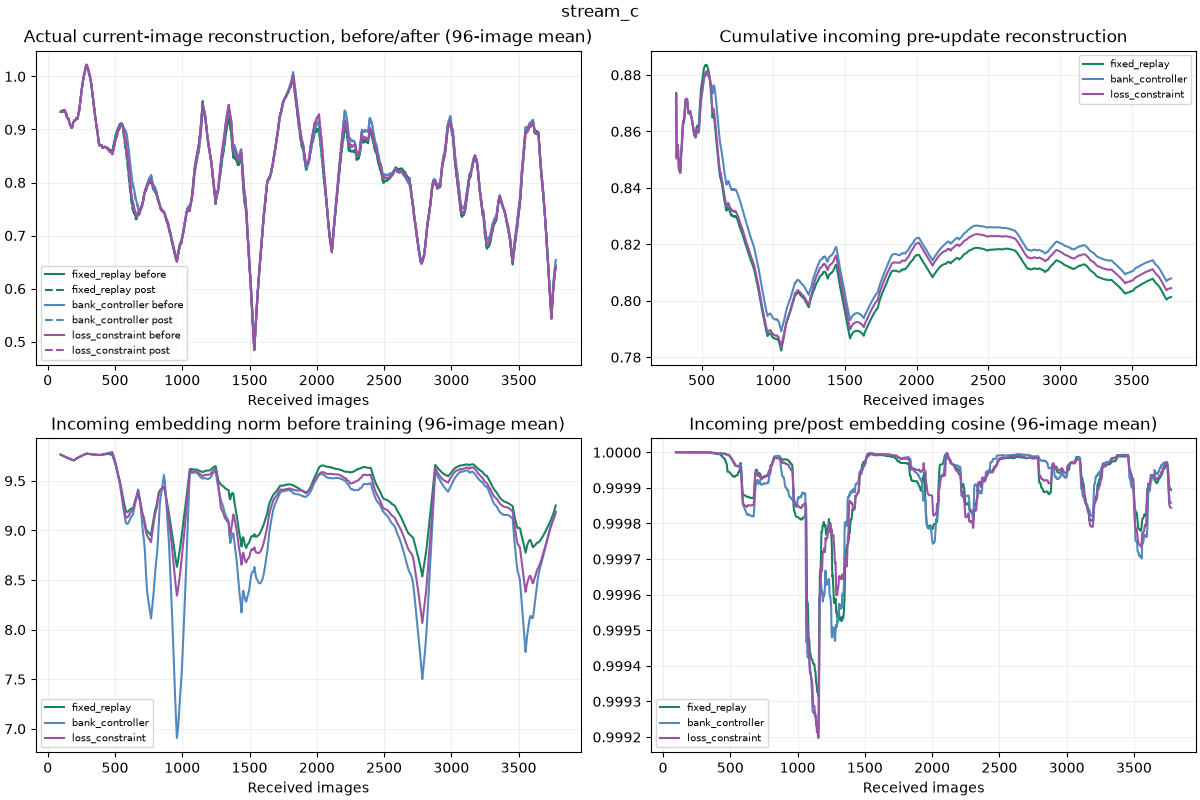

### Retained and recent population health
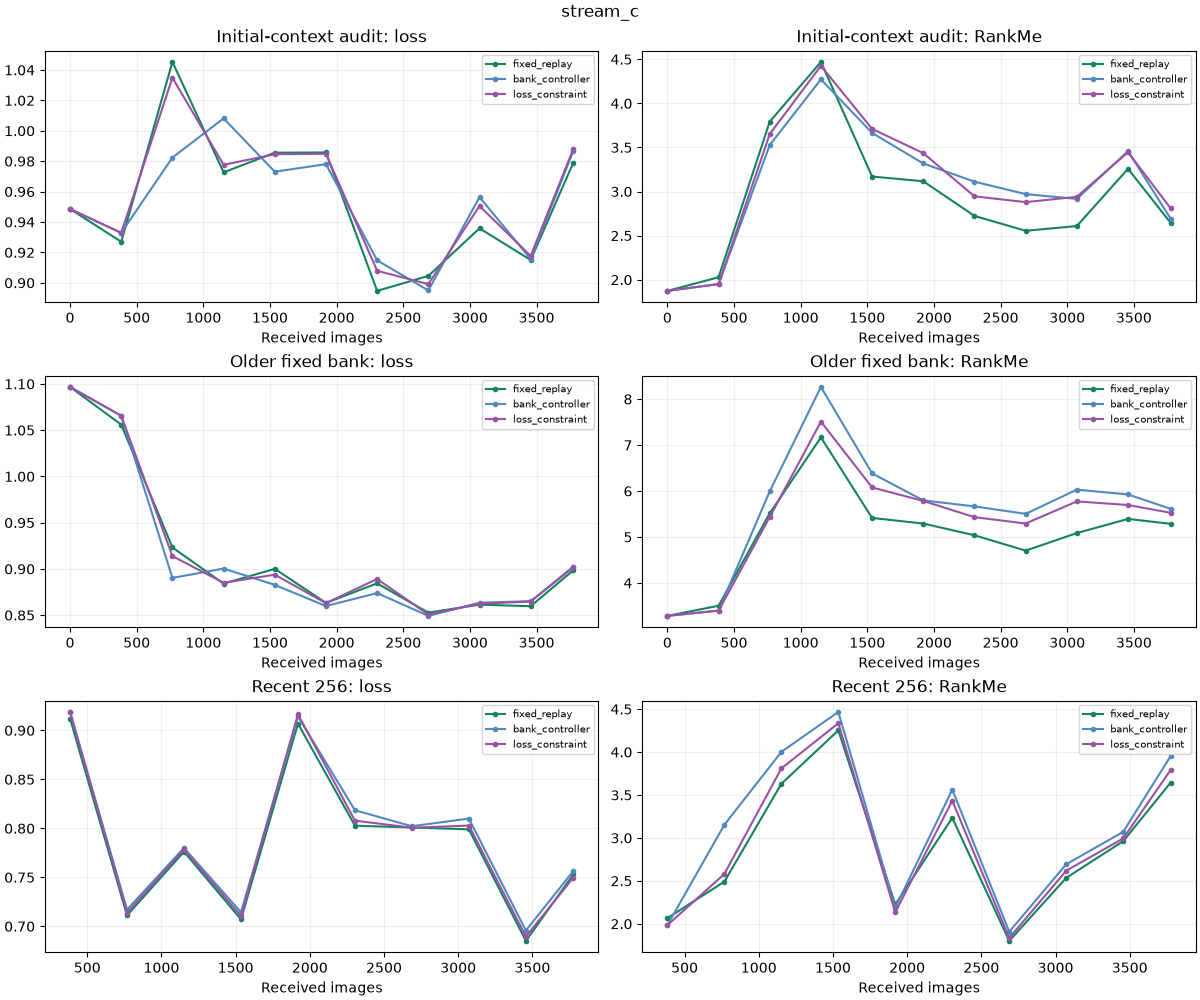

### Actual controller health, actions and LR dose
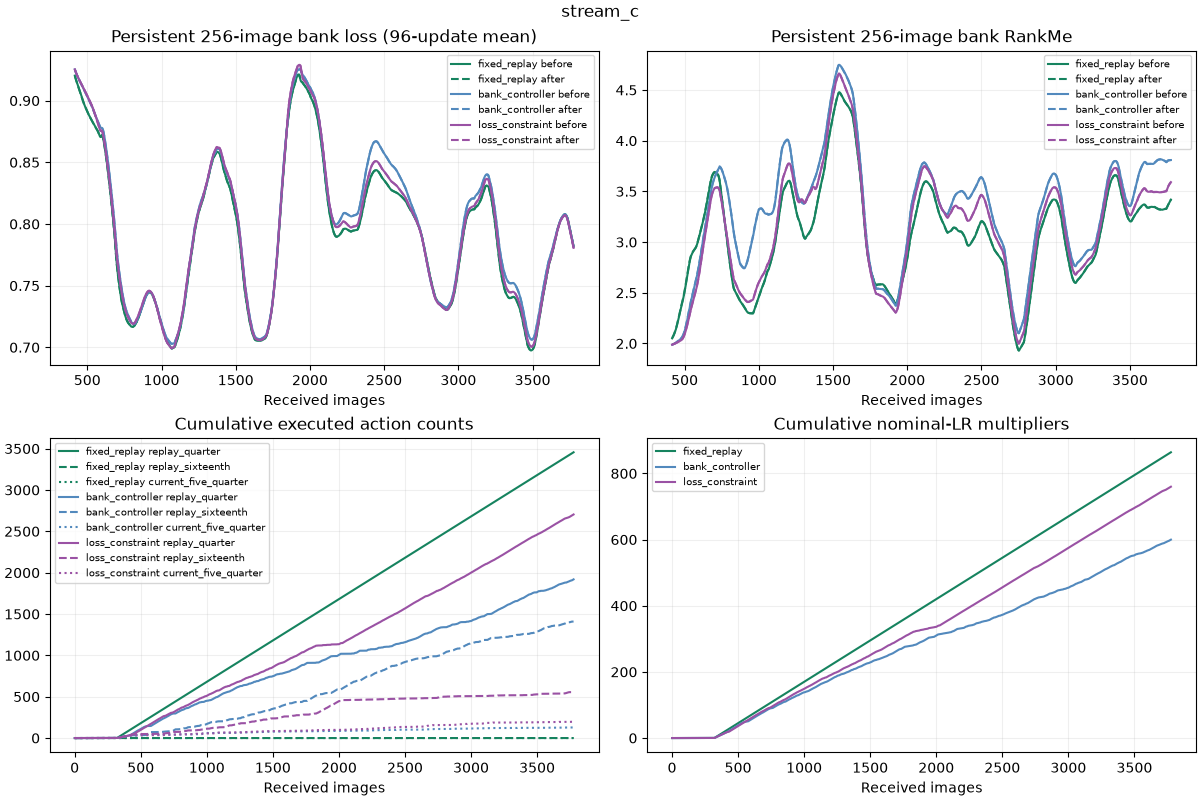

### Persistent image histories and membership effects
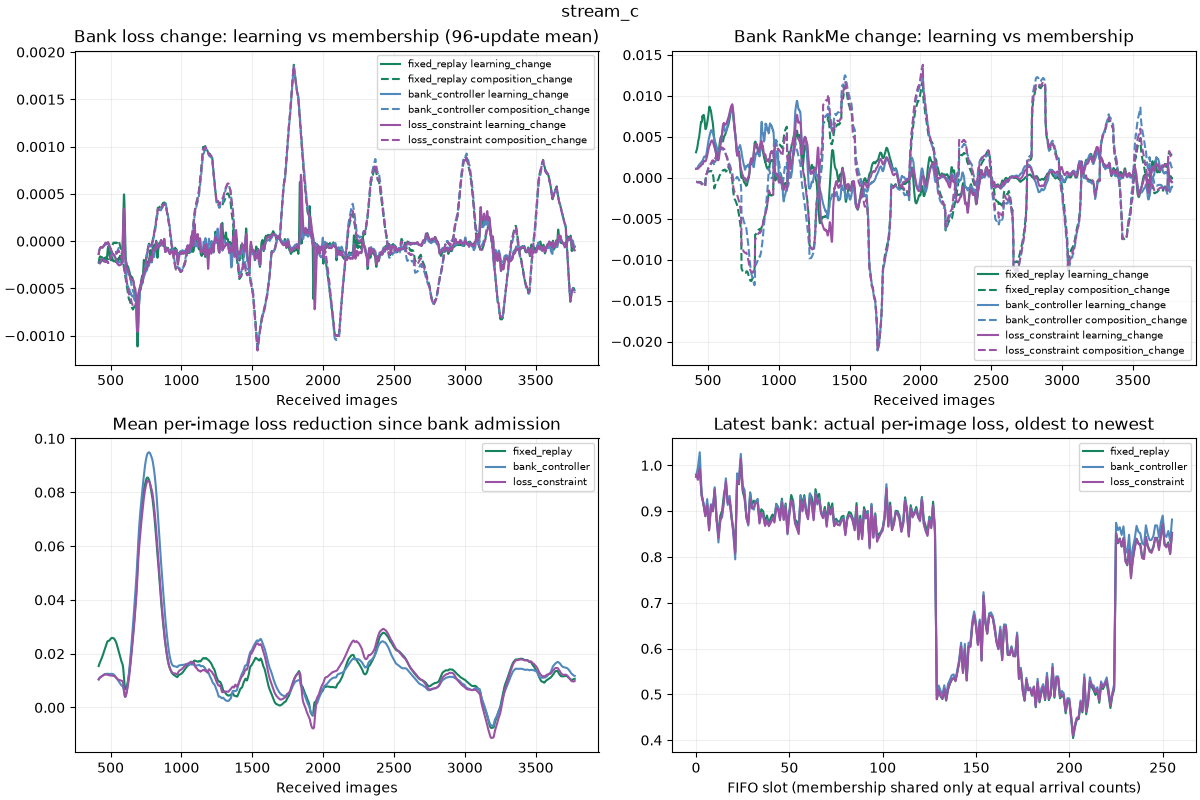

### stream_a: incoming (completed)
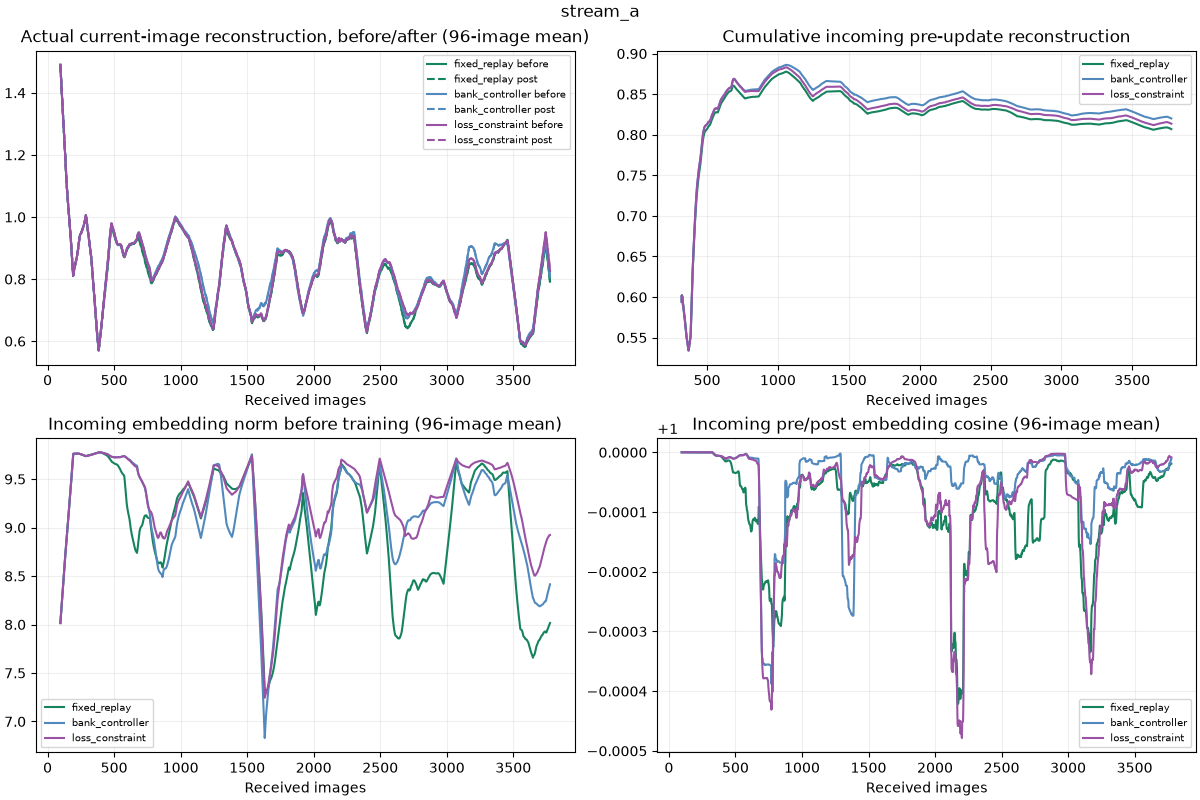

### stream_a: audits (completed)
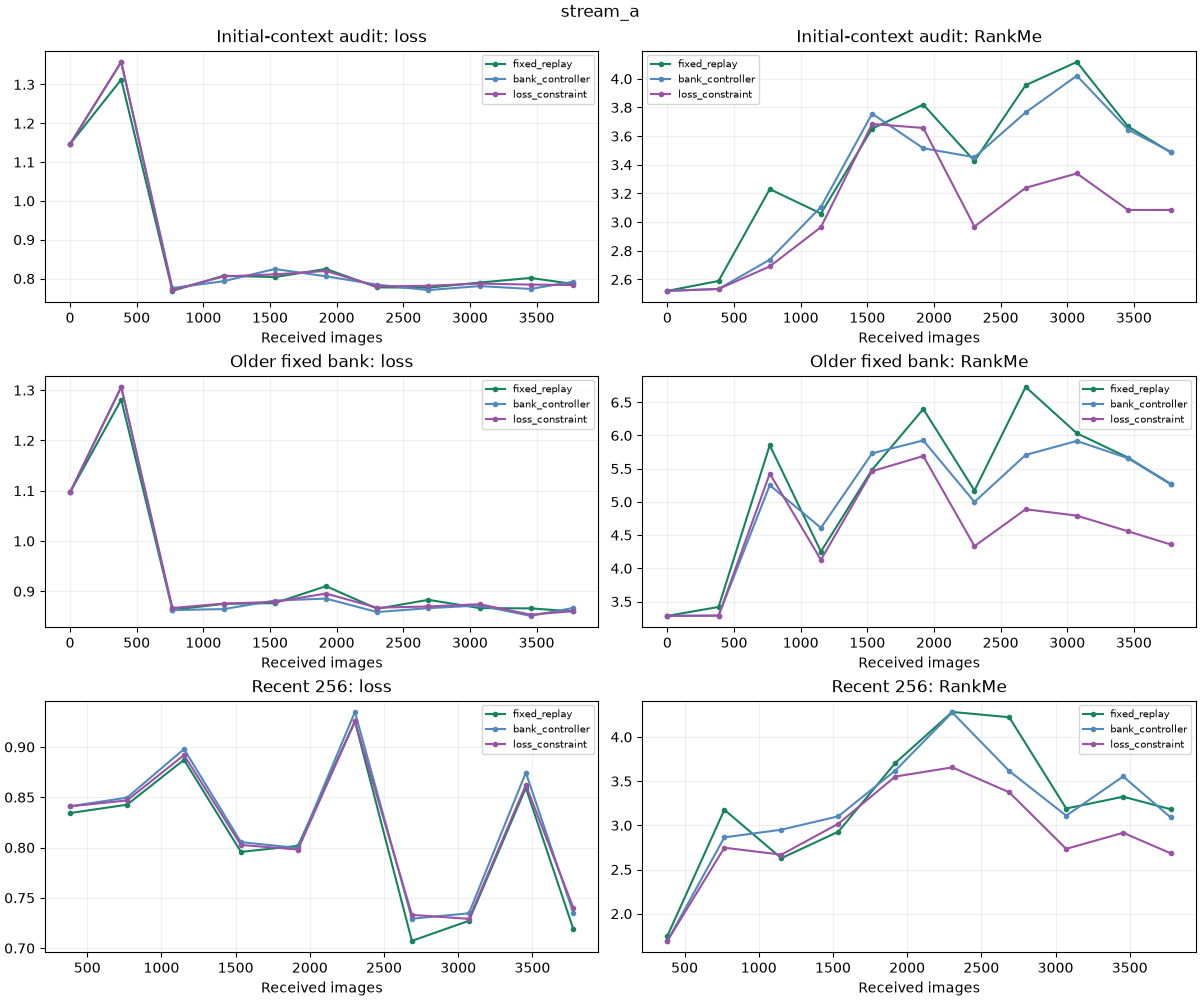

### stream_a: control (completed)
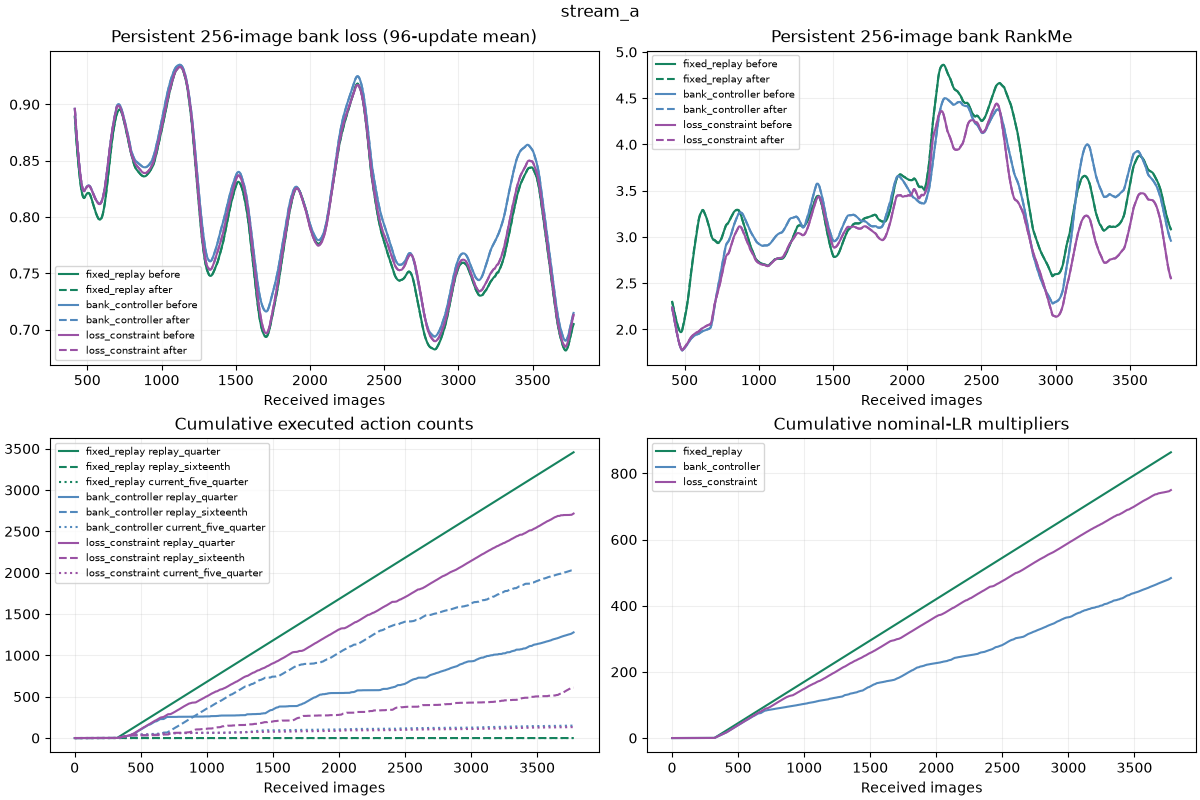

### stream_a: membership (completed)
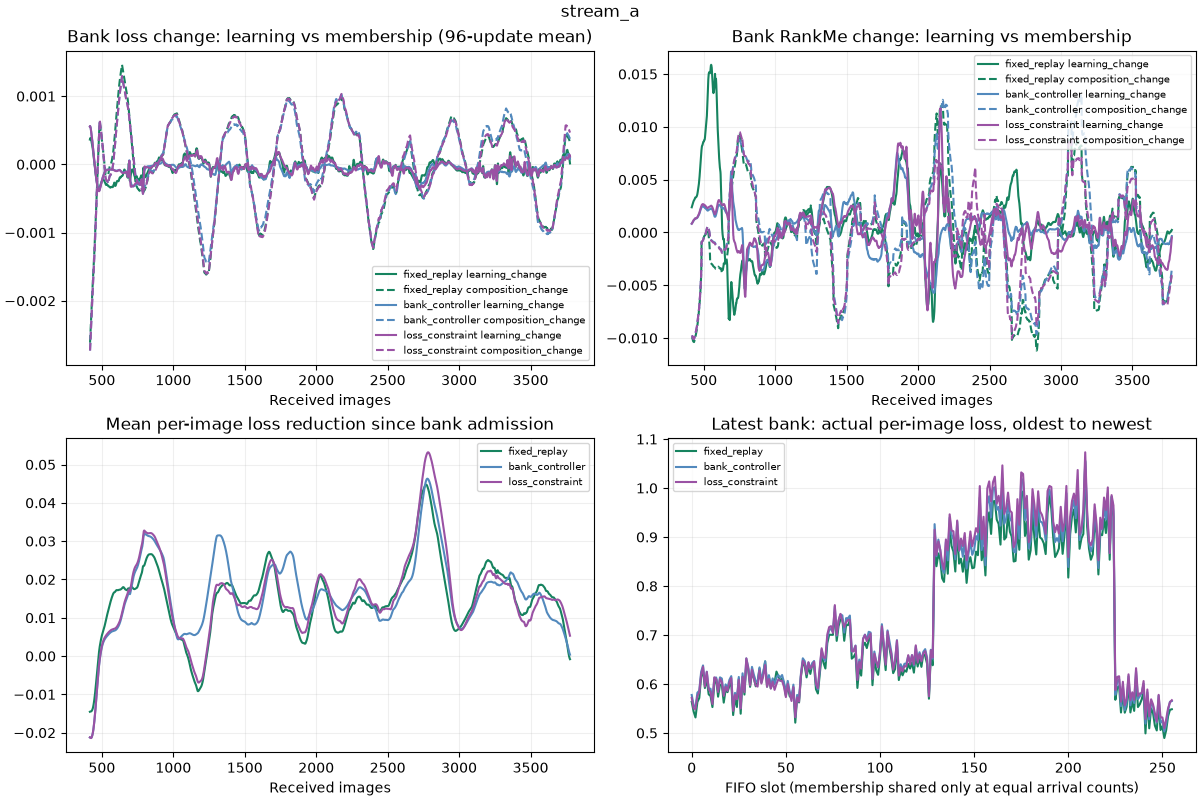

### stream_b: incoming (completed)
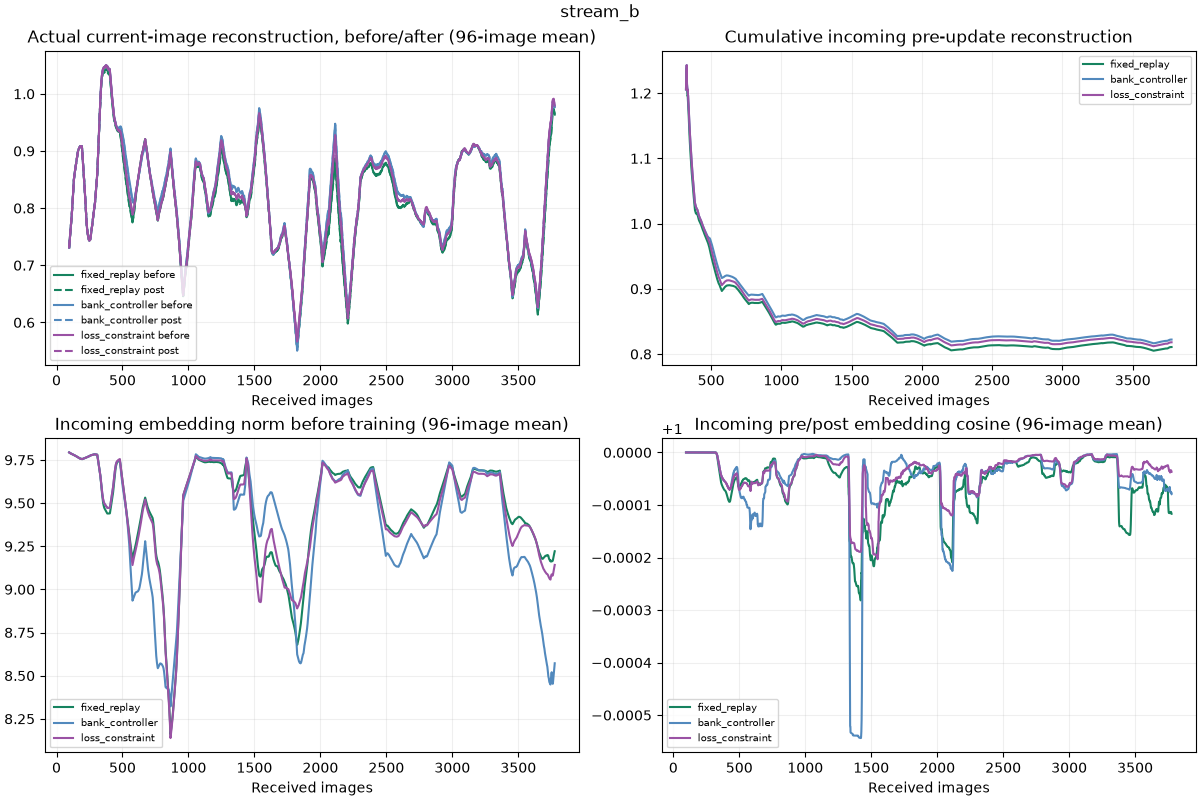

### stream_b: audits (completed)
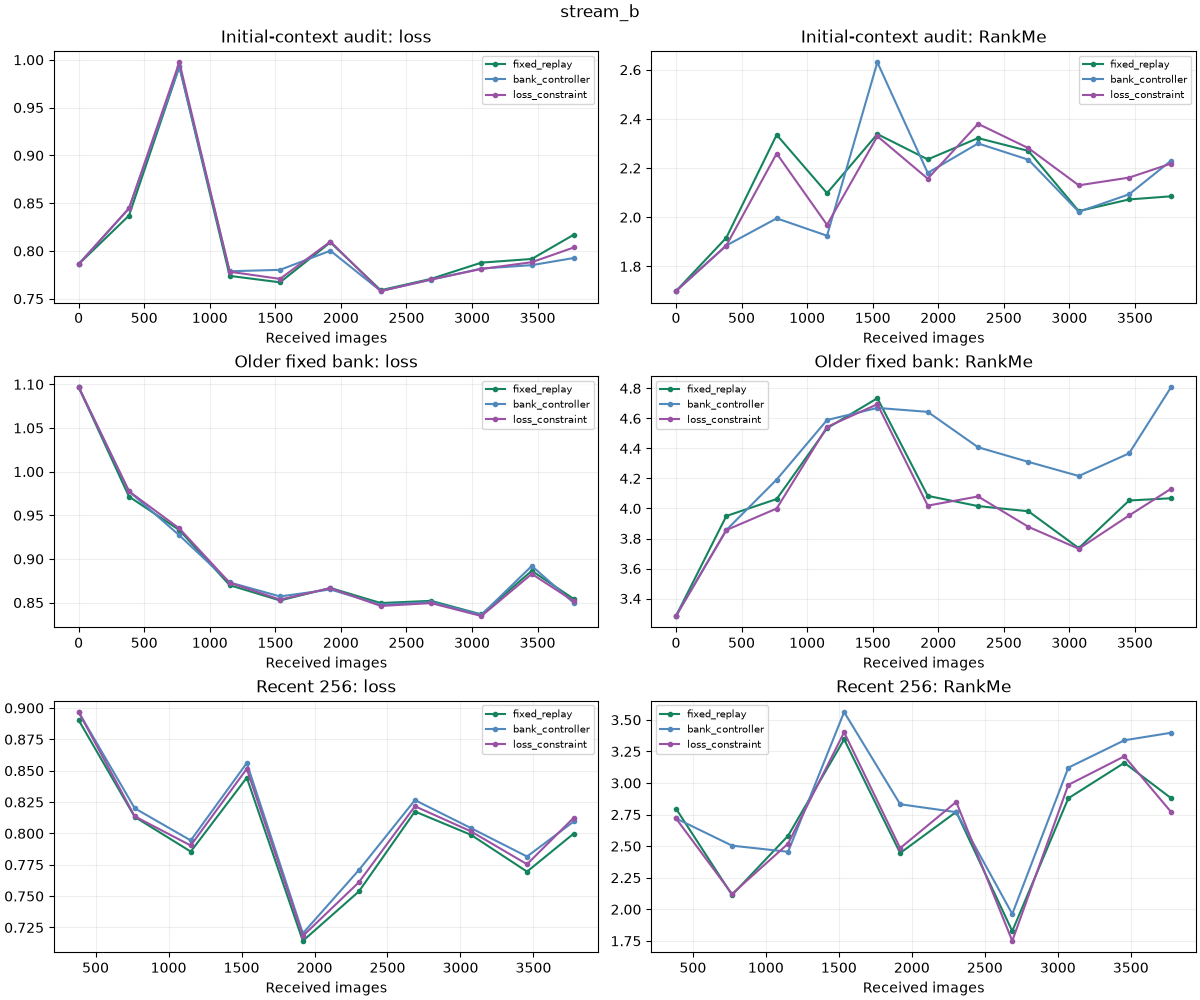

### stream_b: control (completed)
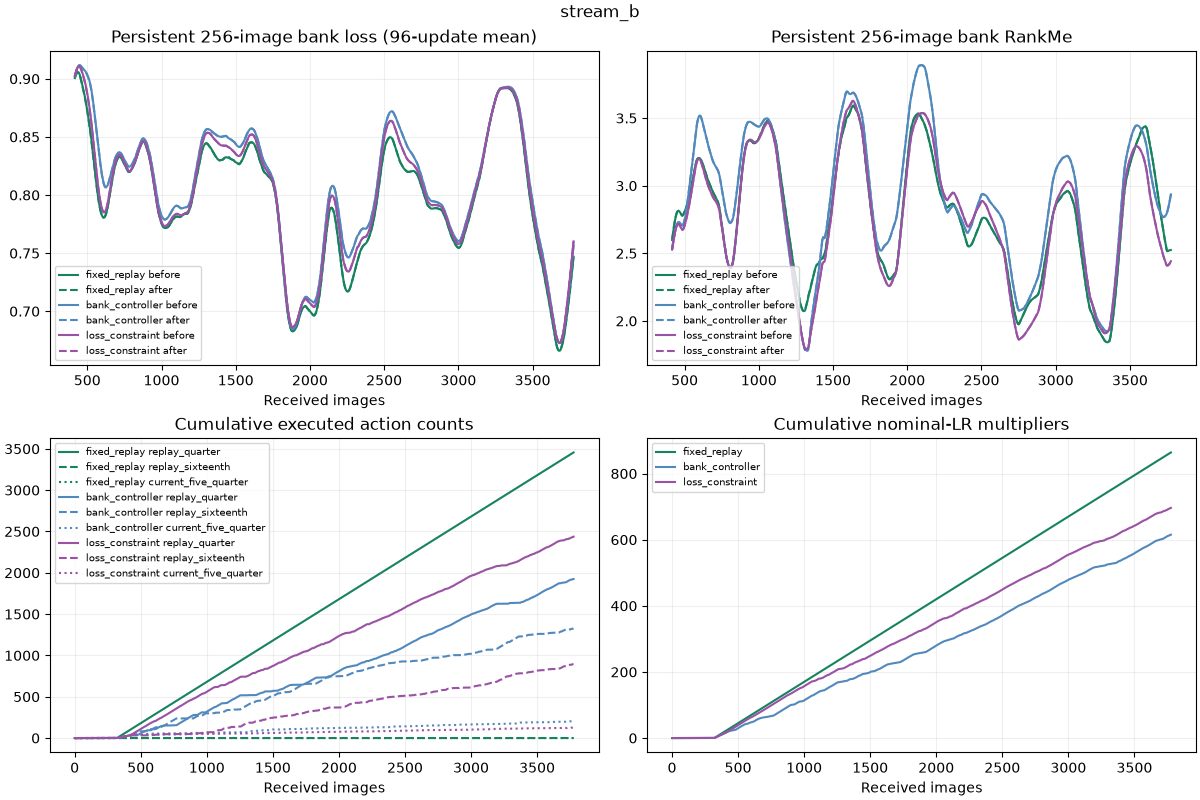

### stream_b: membership (completed)
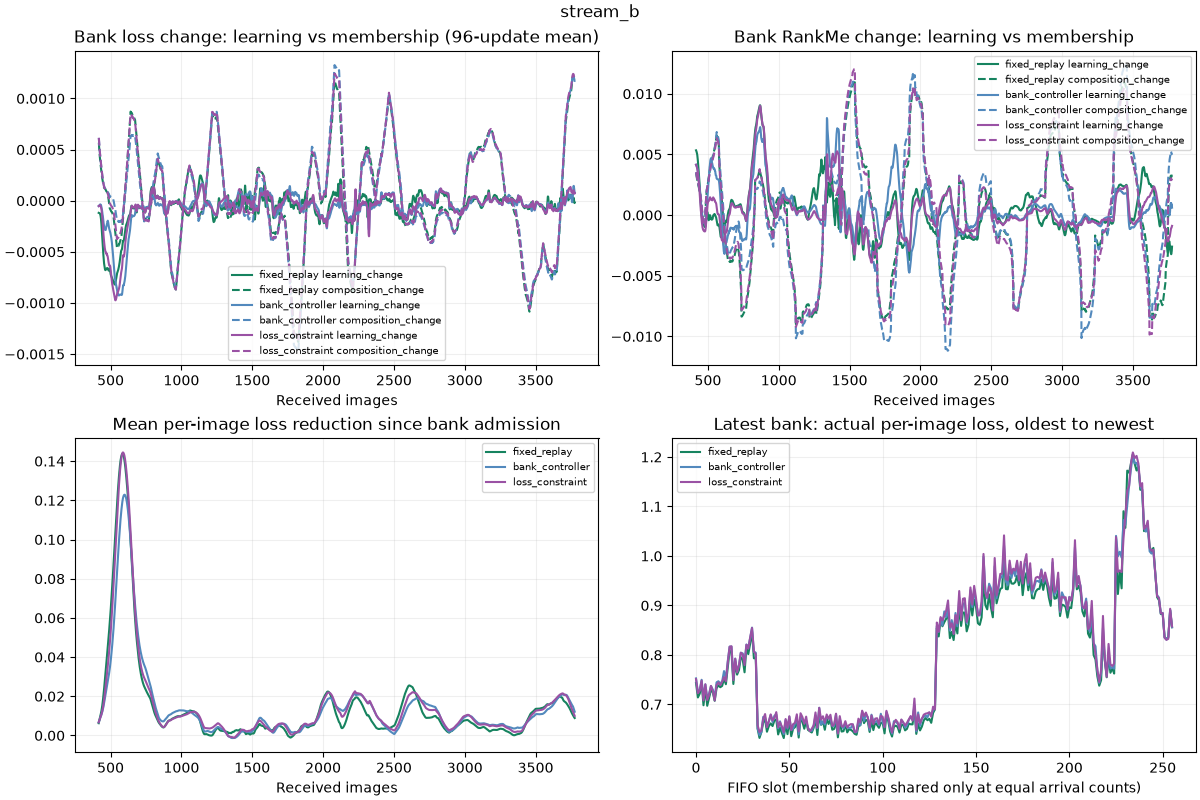